# Введение в ИИ. Коллоквиум. Компьютерная часть

Привет! Это компьютерная часть коллоквиума. На неё отводится 30 минут.

Задания разделены на 2 части:

1. **[6 баллов]** Подготовка данных и классификация с помощью `scikit-learn`.

2. **[4 балла]** Градиентный спуск: реализация и эксперименты с темпом обучения.

**Правила**:

* в ячейках ниже напиши или допиши код, а там, где требуется — текст;
* перед сдачей повторно выполни все ячейки;
* для сдачи загрузи в LMS своё решение в виде файла формата .ipynb.

**Можно пользоваться**:

* Google Colab или Jupyter Notebook;
* библиотеками numpy, pandas, matplotlib, seaborn и scikit-learn;
* официальной документацией к этим библиотекам: [numpy](https://numpy.org/doc/stable/), [pandas](https://pandas.pydata.org/docs/), [matplotlib](https://matplotlib.org/stable/), [seaborn](https://seaborn.pydata.org/), [scikit-learn](https://scikit-learn.org/stable/).

**Нельзя пользоваться**:

* другими средами разработки и библиотеками;
* нейросетями, в том числе в Colab;
* телефоном;
* посторонними вкладками, в том числе поисковыми системами;
* файлами, кроме этого ноутбука и датасетов, на которые он ссылается;
* бумажными записями;
* чужим решением.

**Решение оценивается в 0 баллов, если**:

* в коде содержится готовый ответ;
* вывод ячеек не соответствует написанному коду.

## Часть 1 [6 баллов] Пингвины на льдине

В этой части поработаем с датасетом Palmer Penguins, в котором собраны измерения пингвинов трёх видов с архипелага Палмера в Антарктике. Таргет — бинарная величина `male`: 1, если пингвин — самец, и 0, если самка.

### Описание датасета

male — пол пингвина (1 — самец, 0 — самка), целевая переменная.

species — вид (Adelie, Chinstrap или Gentoo).

island — остров, на котором наблюдали пингвина (Biscoe, Dream или Torgersen).

bill_length_mm — длина клюва в миллиметрах.

bill_depth_mm — высота клюва в миллиметрах.

flipper_length_mm — длина ласта в миллиметрах.

body_mass_g — масса тела в граммах.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

df = sns.load_dataset("penguins")

# Закодируем пол числами; если пол неизвестен, в male останется NaN
df["male"] = df["sex"].map({"Female": 0, "Male": 1})
df = df[["male", "species", "island", "bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]]

display(df.head())
print(df.shape)

,male,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,1.0,Adelie,Torgersen,39.1,18.7,181.0,3750.0
1,0.0,Adelie,Torgersen,39.5,17.4,186.0,3800.0
2,0.0,Adelie,Torgersen,40.3,18.0,195.0,3250.0
3,NaN,Adelie,Torgersen,NaN,NaN,NaN,NaN
4,0.0,Adelie,Torgersen,36.7,19.3,193.0,3450.0


(344, 7)


### Задание 1 [2 балла]

Подготовь данные к обучению.

1. Выведи долю пропусков в каждом столбце **[0,5 балла]**

In [ ]:
# Твой код
display(df.isna().mean())
display(df.isna().sum())

,0
male,0.031977
species,0.000000
island,0.000000
bill_length_mm,0.005814
bill_depth_mm,0.005814
flipper_length_mm,0.005814
body_mass_g,0.005814


,0
male,11
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2


2. Удали строки, в которых неизвестен таргет `male`, и проверь, остались ли после этого пропуски в признаках. Объясни, почему ты поступил именно так **[0,5 балла]**

In [ ]:
# Твой код
df = df[df["male"].notna()]
display(df)

,male,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,1.0,Adelie,Torgersen,39.1,18.7,181.0,3750.0
1,0.0,Adelie,Torgersen,39.5,17.4,186.0,3800.0
2,0.0,Adelie,Torgersen,40.3,18.0,195.0,3250.0
4,0.0,Adelie,Torgersen,36.7,19.3,193.0,3450.0
5,1.0,Adelie,Torgersen,39.3,20.6,190.0,3650.0
...,...,...,...,...,...,...,...
338,0.0,Gentoo,Biscoe,47.2,13.7,214.0,4925.0
340,0.0,Gentoo,Biscoe,46.8,14.3,215.0,4850.0
341,1.0,Gentoo,Biscoe,50.4,15.7,222.0,5750.0
342,0.0,Gentoo,Biscoe,45.2,14.8,212.0,5200.0


In [ ]:
df.isna().mean()

,0
male,0.0
species,0.0
island,0.0
bill_length_mm,0.0
bill_depth_mm,0.0
flipper_length_mm,0.0
body_mass_g,0.0


Твой ответ

3. Закодируй категориальные признаки `species` и `island` с помощью One-Hot Encoding **[0,5 балла]**

In [ ]:
# Твой код

from typing import cast

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

ct = ColumnTransformer(
    [("oha", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["species", "island"])],
    remainder="passthrough",
    verbose_feature_names_out=False,
)
ct.set_output(transform="pandas")

df_encoded = cast(pd.DataFrame, ct.fit_transform(df))
display(df_encoded.head())

,species_Adelie,species_Chinstrap,species_Gentoo,island_Biscoe,island_Dream,island_Torgersen,male,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,39.1,18.7,181.0,3750.0
1,1.0,0.0,0.0,0.0,0.0,1.0,0.0,39.5,17.4,186.0,3800.0
2,1.0,0.0,0.0,0.0,0.0,1.0,0.0,40.3,18.0,195.0,3250.0
4,1.0,0.0,0.0,0.0,0.0,1.0,0.0,36.7,19.3,193.0,3450.0
5,1.0,0.0,0.0,0.0,0.0,1.0,1.0,39.3,20.6,190.0,3650.0


4. Отдели таргет от признаков и раздели данные на обучающую и тестовую выборки в отношении 75 к 25 с `stratify=y` **[0,5 балла]**

In [ ]:
from sklearn.model_selection import train_test_split

random_state = 42

# Твой код
X = df_encoded.drop(columns="male")
Y = df_encoded["male"]

x_train, x_test, y_train, y_test = train_test_split(
    X, Y,
    test_size=0.25,
    stratify=Y,
    random_state=random_state,
)

x_train = cast(pd.DataFrame, x_train)
y_train = cast(pd.DataFrame, y_train)
x_test = cast(pd.DataFrame, x_test)
y_test = cast(pd.DataFrame, y_test)



### Задание 2 [4 балла]

Теперь обучи модель классификации.

1. Обучи логистическую регрессию `LogisticRegression(max_iter=1000)` на обучающей выборке и посчитай Accuracy на тестовой. Сравни её с константной моделью, которая всем предсказывает самый частый класс обучающей выборки **[1 балл]**

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score

# Твой код
model = LogisticRegression(max_iter=1000)
model.fit(x_train, y_train)

y_pred = model.predict(x_test)
print(f"{accuracy_score(y_test, y_pred)=}")
print(f"{accuracy_score(y_test, np.full(len(y_test), y_train.mode()[0]))=}")


accuracy_score(y_test, y_pred)=0.9166666666666666
accuracy_score(y_test, np.full(len(y_test), y_train.mode()[0]))=0.5


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


2. С помощью `predict_proba` получи вероятности того, что пингвин — самец, для тестовой выборки. Посчитай Accuracy, Precision и Recall при порогах $0{,}3$, $0{,}5$ и $0{,}7$ и выведи их в одной таблице **[2 балла]**

In [ ]:
# Твой код
proba = model.predict_proba(x_test)[:, 1]
results_dict = []
for threshold in [0.3, 0.5, 0.7]:
    y_pred = (proba >= threshold).astype(int)
    results_dict.append({
        "threshold": threshold,
        "accuracy_score": accuracy_score(y_test, y_pred),
        "precision_score": precision_score(y_test, y_pred),
        "recall_score": recall_score(y_test, y_pred),
    })
results = pd.DataFrame(results_dict)
display(results)


,threshold,accuracy_score,precision_score,recall_score
0,0.3,0.904762,0.854167,0.976190
1,0.5,0.916667,0.906977,0.928571
2,0.7,0.904762,0.925000,0.880952


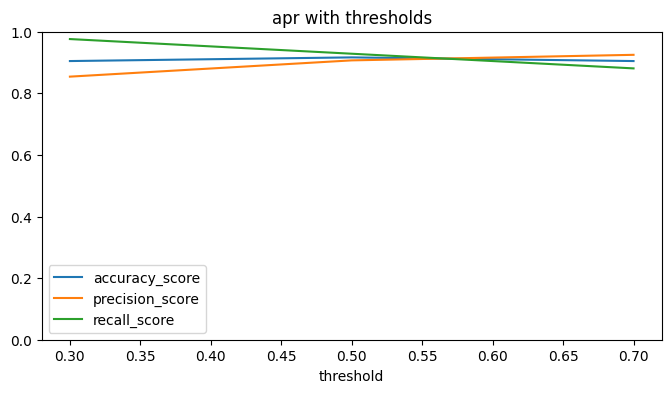

In [ ]:
from matplotlib.figure import Figure
from matplotlib.pylab import Axes

fig: Figure
ax: Axes
fig, ax = plt.subplots(figsize=(8, 4))
results.set_index("threshold").plot(ax=ax)
ax.set_title("apr with thresholds")
_ = ax.set_ylim(0, 1)


3. Как меняются Precision и Recall с ростом порога? Объясни, почему так происходит **[1 балл]**

Твой ответ

## Часть 2 [4 балла] Овраг

### Задание 3 [4 балла]

Ниже дана функция двух переменных:

$$
g(x, y) = x^2 + 10y^2.
$$

Исследуй, как темп обучения влияет на работу градиентного спуска.

1. Допиши функцию `gradient_descent`: она должна сделать `n_iter` шагов градиентного спуска из точки `z0` с темпом обучения `learning_rate` и вернуть массив всех точек траектории **[1,5 балла]**

In [ ]:
def g(z):
    x, y = z
    return x**2 + 10 * y**2


def grad_g(z):
    x, y = z
    return np.array([2 * x, 20 * y])


def gradient_descent(grad, z0, learning_rate, n_iter):
    # твой код
    pass

2. Запусти алгоритм из точки $(4, 2)$ на 30 итераций с тремя значениями темпа обучения: $0{,}02$, $0{,}09$ и $0{,}12$. Для каждого значения выведи полученную точку и значение функции в ней. Траекторию сохрани в словарь `paths`: при помощи него ниже построй графики координаты `y` по итерациям **[1 балл]**

In [ ]:
learning_rates = [0.02, 0.09, 0.12]
z0 = np.array([4.0, 2.0])
paths = {}

# Твой код

KeyError: 0.02

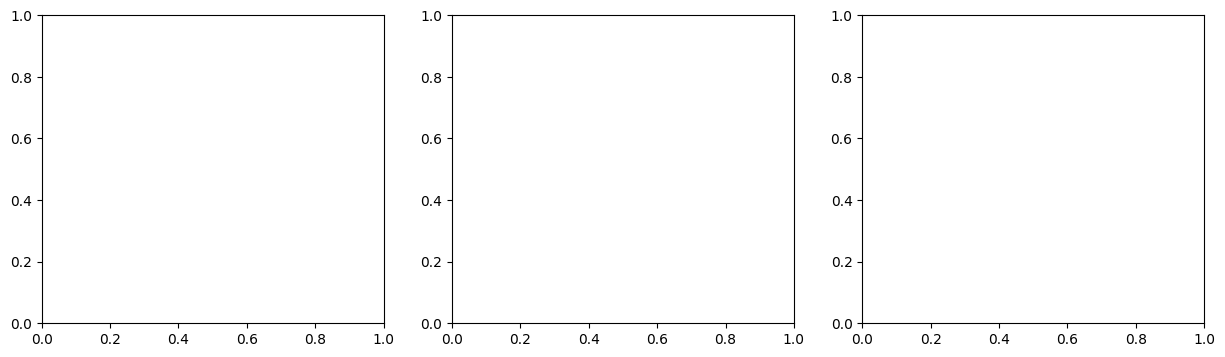

In [ ]:
# Готовый код для графика, менять его не нужно
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, lr in zip(axes, learning_rates):
    ax.plot(paths[lr][:, 1], marker="o", markersize=3)
    ax.set_title(f"Темп обучения {lr}")
    ax.set_xlabel("Итерация")
    ax.set_ylabel("y")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

3. Напиши выводы: что происходит при каждом значении темпа обучения и почему? **[1,5 балла]**

Твой ответ